# IPP Practical File 2

Swanand Wirkar 20251051 BDA

## Problem Statement

Problem 2: Noise Sensitivity Experiment
Load a clean grayscale image, add Gaussian and salt-and-pepper noise, then apply Sobel and Laplacian. Evaluate noise sensitivity, edge clarity, and useful preprocessing.

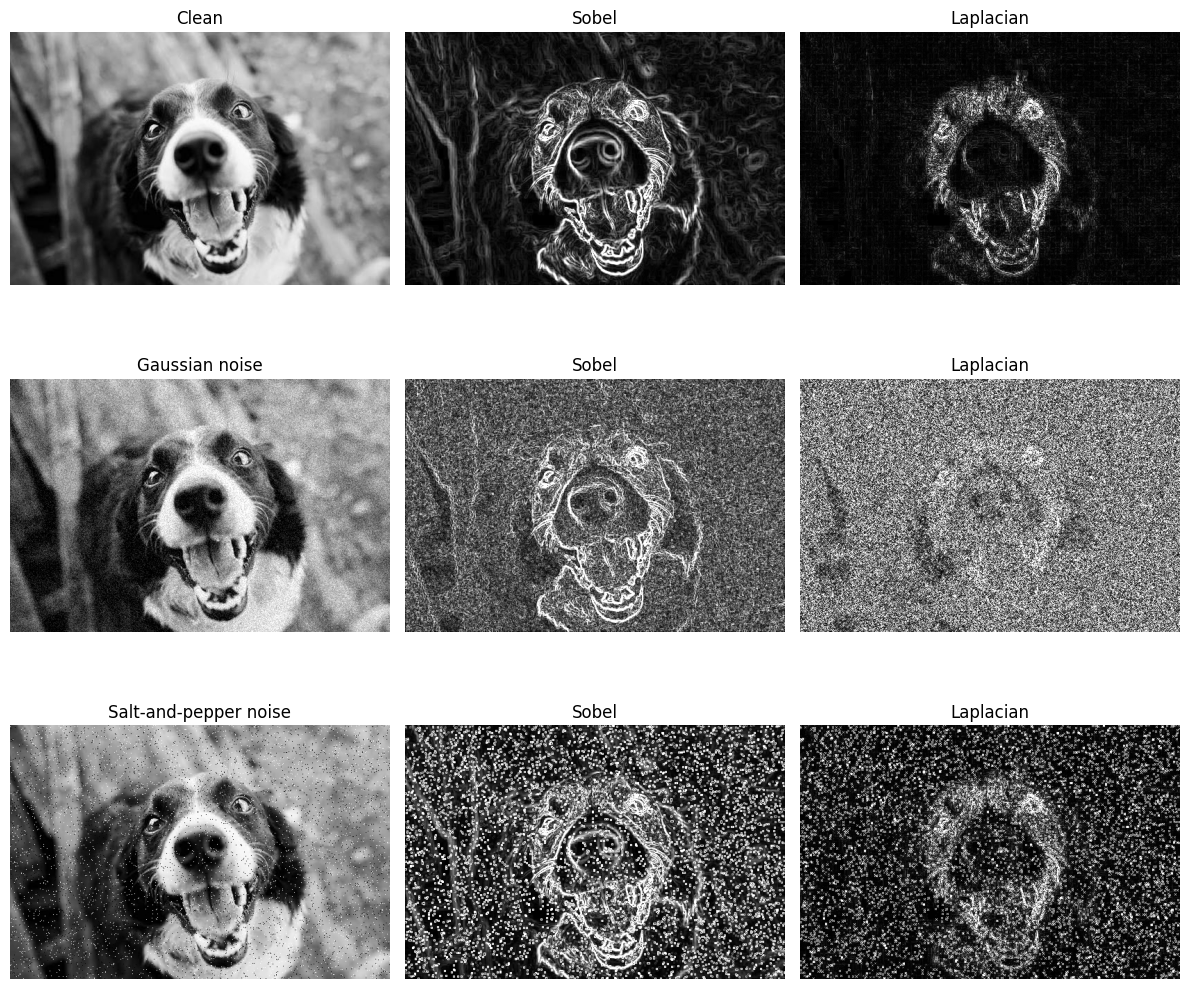

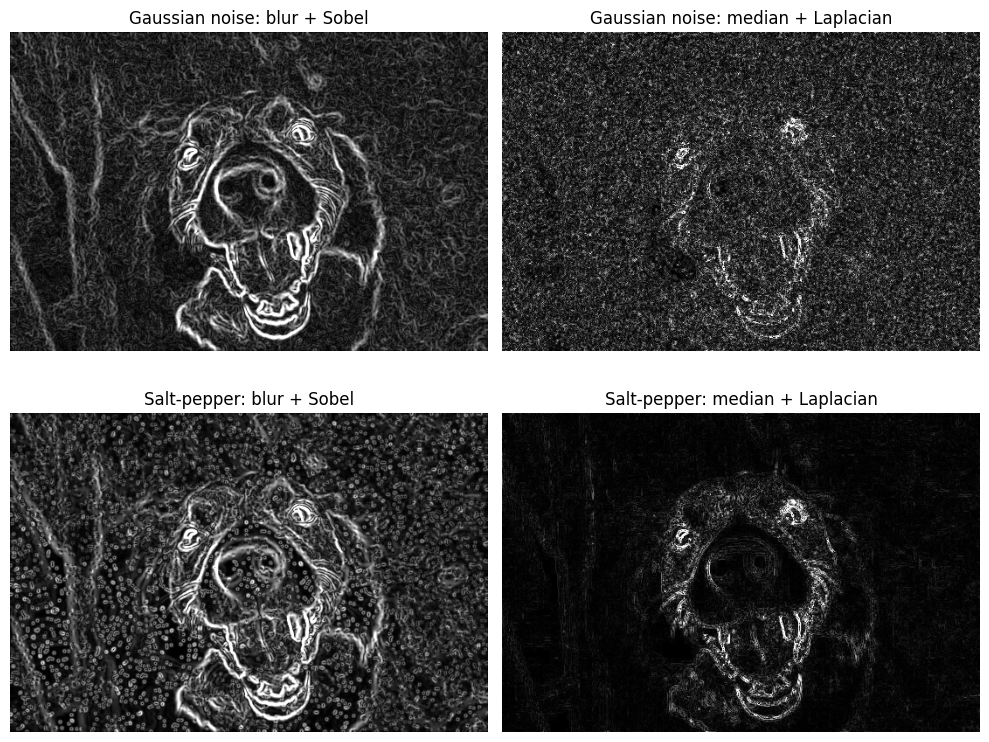

Laplacian usually amplifies noise more because it uses second derivatives. Noise adds false edge responses and reduces clarity. Gaussian blur is useful for Gaussian noise; median filtering is especially effective for salt-and-pepper noise. Filtering may also soften fine edges.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("clean_image.jpg", cv2.IMREAD_GRAYSCALE)
if image is None:
    raise FileNotFoundError("Place a clean image named clean_image.jpg in the notebook folder.")
rng = np.random.default_rng(42)
gaussian = np.clip(image.astype(np.float32) + rng.normal(0, 20, image.shape), 0, 255).astype(np.uint8)
sp = image.copy(); r = rng.random(image.shape); sp[r < 0.02] = 0; sp[r > 0.98] = 255

def edges(img, method):
    if method == "Sobel":
        gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3); gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
        return cv2.convertScaleAbs(cv2.magnitude(gx, gy))
    return cv2.convertScaleAbs(cv2.Laplacian(img, cv2.CV_64F, ksize=3))

samples = [("Clean", image), ("Gaussian noise", gaussian), ("Salt-and-pepper noise", sp)]
fig, ax = plt.subplots(3, 3, figsize=(12, 11))
for i, (name, img) in enumerate(samples):
    ax[i,0].imshow(img, cmap="gray"); ax[i,0].set_title(name)
    ax[i,1].imshow(edges(img, "Sobel"), cmap="gray"); ax[i,1].set_title("Sobel")
    ax[i,2].imshow(edges(img, "Laplacian"), cmap="gray"); ax[i,2].set_title("Laplacian")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
ax[0,0].imshow(edges(cv2.GaussianBlur(gaussian,(5,5),1), "Sobel"), cmap="gray"); ax[0,0].set_title("Gaussian noise: blur + Sobel")
ax[0,1].imshow(edges(cv2.medianBlur(gaussian,3), "Laplacian"), cmap="gray"); ax[0,1].set_title("Gaussian noise: median + Laplacian")
ax[1,0].imshow(edges(cv2.GaussianBlur(sp,(5,5),1), "Sobel"), cmap="gray"); ax[1,0].set_title("Salt-pepper: blur + Sobel")
ax[1,1].imshow(edges(cv2.medianBlur(sp,3), "Laplacian"), cmap="gray"); ax[1,1].set_title("Salt-pepper: median + Laplacian")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
print("Laplacian usually amplifies noise more because it uses second derivatives. Noise adds false edge responses and reduces clarity. Gaussian blur is useful for Gaussian noise; median filtering is especially effective for salt-and-pepper noise. Filtering may also soften fine edges.")